# Model-prioritised gene expression

The eight model-prioritised genes are H3C14, KIAA2012, MYEOV, TMPRSS4, ZNF549, GDAP1, RUNDC3B and ZNF205, selected as described in thesis §3.11 and Table 4.18. Membership is independent of downstream significance. The cohort contains 110 patients: 43 oligo and 67 poly. These same-cohort post-selection comparisons are exploratory, not independent validation.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import plot_thesis_saved_figure
RESULTS = Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/MCPP-Biological-Characterization/common-110/harmonised_main8')

## Frozen model evidence

In [ ]:
evidence = pd.read_csv(RESULTS / 'harmonised_only_82_gene_evidence.csv')
display(evidence.loc[evidence.main_set].sort_values('best_shap_rank').style.format(precision=3))

,gene_symbol,ensembl_gene_id,best_shap_rank,transcriptomic_RF_folds,three_modality_RF_folds,mean_abs_shap,main_set
28,H3C14,ENSG00000203811,2.000,3,2,0.035,True
30,KIAA2012,ENSG00000182329,4.000,2,3,0.017,True
37,MYEOV,ENSG00000172927,6.000,2,4,0.013,True
70,TMPRSS4,ENSG00000137648,9.000,3,3,0.010,True
81,ZNF549,ENSG00000121406,12.000,4,3,0.008,True
25,GDAP1,ENSG00000104381,15.000,5,3,0.008,True
54,RUNDC3B,ENSG00000105784,18.000,3,3,0.007,True
79,ZNF205,ENSG00000122386,19.000,3,1,0.006,True


## Expression methods

Supplied log2(TPM + 1) expression; two-sided asymptotic, tie-corrected Mann–Whitney U with continuity correction. Cliff’s delta is oriented poly minus oligo. Within-group bootstrap percentile 95% intervals use 10,000 resamples and seed 42. BH is calculated across the eight tests. All eight genes were available for all 110 patients.

In [ ]:
display(pd.read_csv(RESULTS / 'harmonised_only_main8_expression_group_summaries.csv').style.format(precision=3))

gene_symbol,ensembl_gene_id,group,N,median,q1,q3,IQR,mean,SD
GDAP1,ENSG00000104381,Oligometastatic,43,5.59,5.11,6.34,1.23,5.86,1.06
GDAP1,ENSG00000104381,Polymetastatic,67,5.36,4.7,5.6,0.902,4.93,1.55
H3C14,ENSG00000203811,Oligometastatic,43,0,0,0,0,1.45,2.86
H3C14,ENSG00000203811,Polymetastatic,67,0.000869,0,0.0159,0.0159,1.2,2.59
KIAA2012,ENSG00000182329,Oligometastatic,43,3.81,3.43,4.2,0.765,3.87,0.951
KIAA2012,ENSG00000182329,Polymetastatic,67,3.38,2.93,3.78,0.843,3.02,1.23
MYEOV,ENSG00000172927,Oligometastatic,43,2.94,0,4.03,4.03,2.56,2.28
MYEOV,ENSG00000172927,Polymetastatic,67,0,0,2.12,2.12,0.988,1.47
RUNDC3B,ENSG00000105784,Oligometastatic,43,3.24,1.91,4.22,2.31,3.12,2.1
RUNDC3B,ENSG00000105784,Polymetastatic,67,2.06,0,3.03,3.03,1.89,1.68


In [ ]:
display(pd.read_csv(RESULTS / 'harmonised_only_main8_expression_tests.csv')[['gene_symbol', 'N_oligo', 'N_poly', 'cliffs_delta', 'delta_CI_lower', 'delta_CI_upper', 'p_value', 'q_value', 'BH_family_size']].style.format(precision=3))

gene_symbol,N_oligo,N_poly,cliffs_delta,delta_CI_lower,delta_CI_upper,p_value,q_value,BH_family_size
H3C14,43,67,0.4,0.185,0.607,0.000196,0.000618,8
KIAA2012,43,67,-0.418,-0.608,-0.207,0.000232,0.000618,8
MYEOV,43,67,-0.411,-0.599,-0.208,0.000102,0.000618,8
TMPRSS4,43,67,-0.348,-0.54,-0.136,0.00217,0.00347,8
ZNF549,43,67,-0.21,-0.413,0.00798,0.0647,0.0647,8
GDAP1,43,67,-0.304,-0.5,-0.0864,0.00743,0.00849,8
RUNDC3B,43,67,-0.351,-0.554,-0.138,0.00183,0.00347,8
ZNF205,43,67,-0.318,-0.518,-0.106,0.00472,0.0063,8


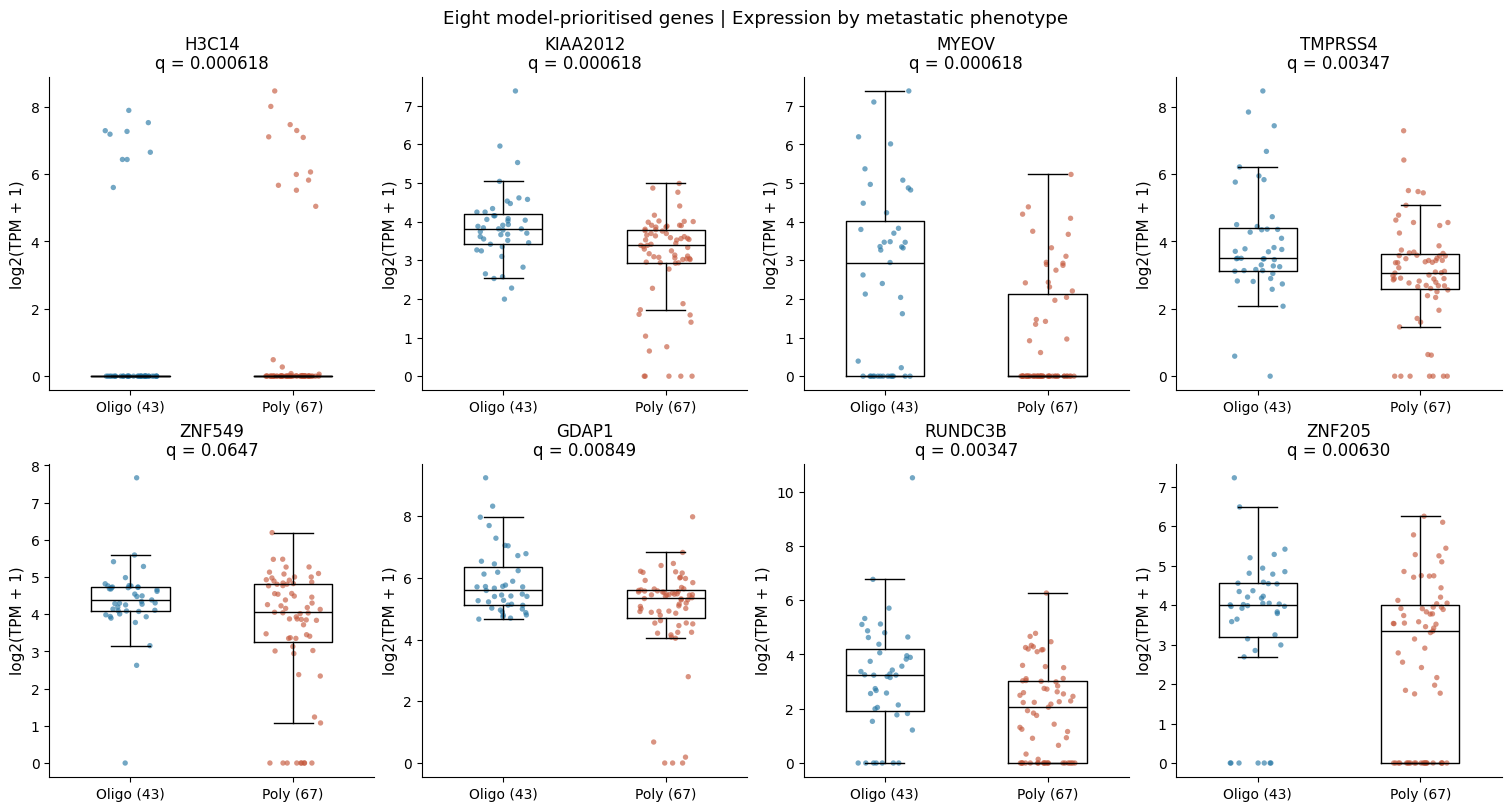

In [25]:
results = pd.read_csv(Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/MCPP-Biological-Characterization/common-110/harmonised_main8/harmonised_only_main8_expression_tests.csv'))
genes = ['H3C14','KIAA2012','MYEOV','TMPRSS4','ZNF549','GDAP1','RUNDC3B','ZNF205']
expected_q_labels = ['0.000618','0.000618','0.000618','0.00347','0.0647','0.00849','0.00347','0.00630']
assert results.gene_symbol.tolist() == genes
q_labels = [format(q, '#.3g') for q in results.q_value]
assert q_labels == expected_q_labels
fig = plot_thesis_saved_figure('expression')
assert len(fig.axes) == 8
np.testing.assert_array_equal(fig.get_size_inches(), [15, 8])
for ax, gene, q_label in zip(fig.axes, genes, q_labels):
    assert ax.get_title() == gene
    ax.set_title(f'{gene}\nq = {q_label}', fontsize=ax.title.get_fontsize())
    ax.title.set_linespacing(1.05)
output_dir = ROOT / 'figures/results/biological_interpretation'
output_dir.mkdir(parents=True, exist_ok=True)
for extension in ['png', 'pdf']:
    fig.savefig(output_dir / f'harmonised_only_main8_expression_thesis_clean.{extension}', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()


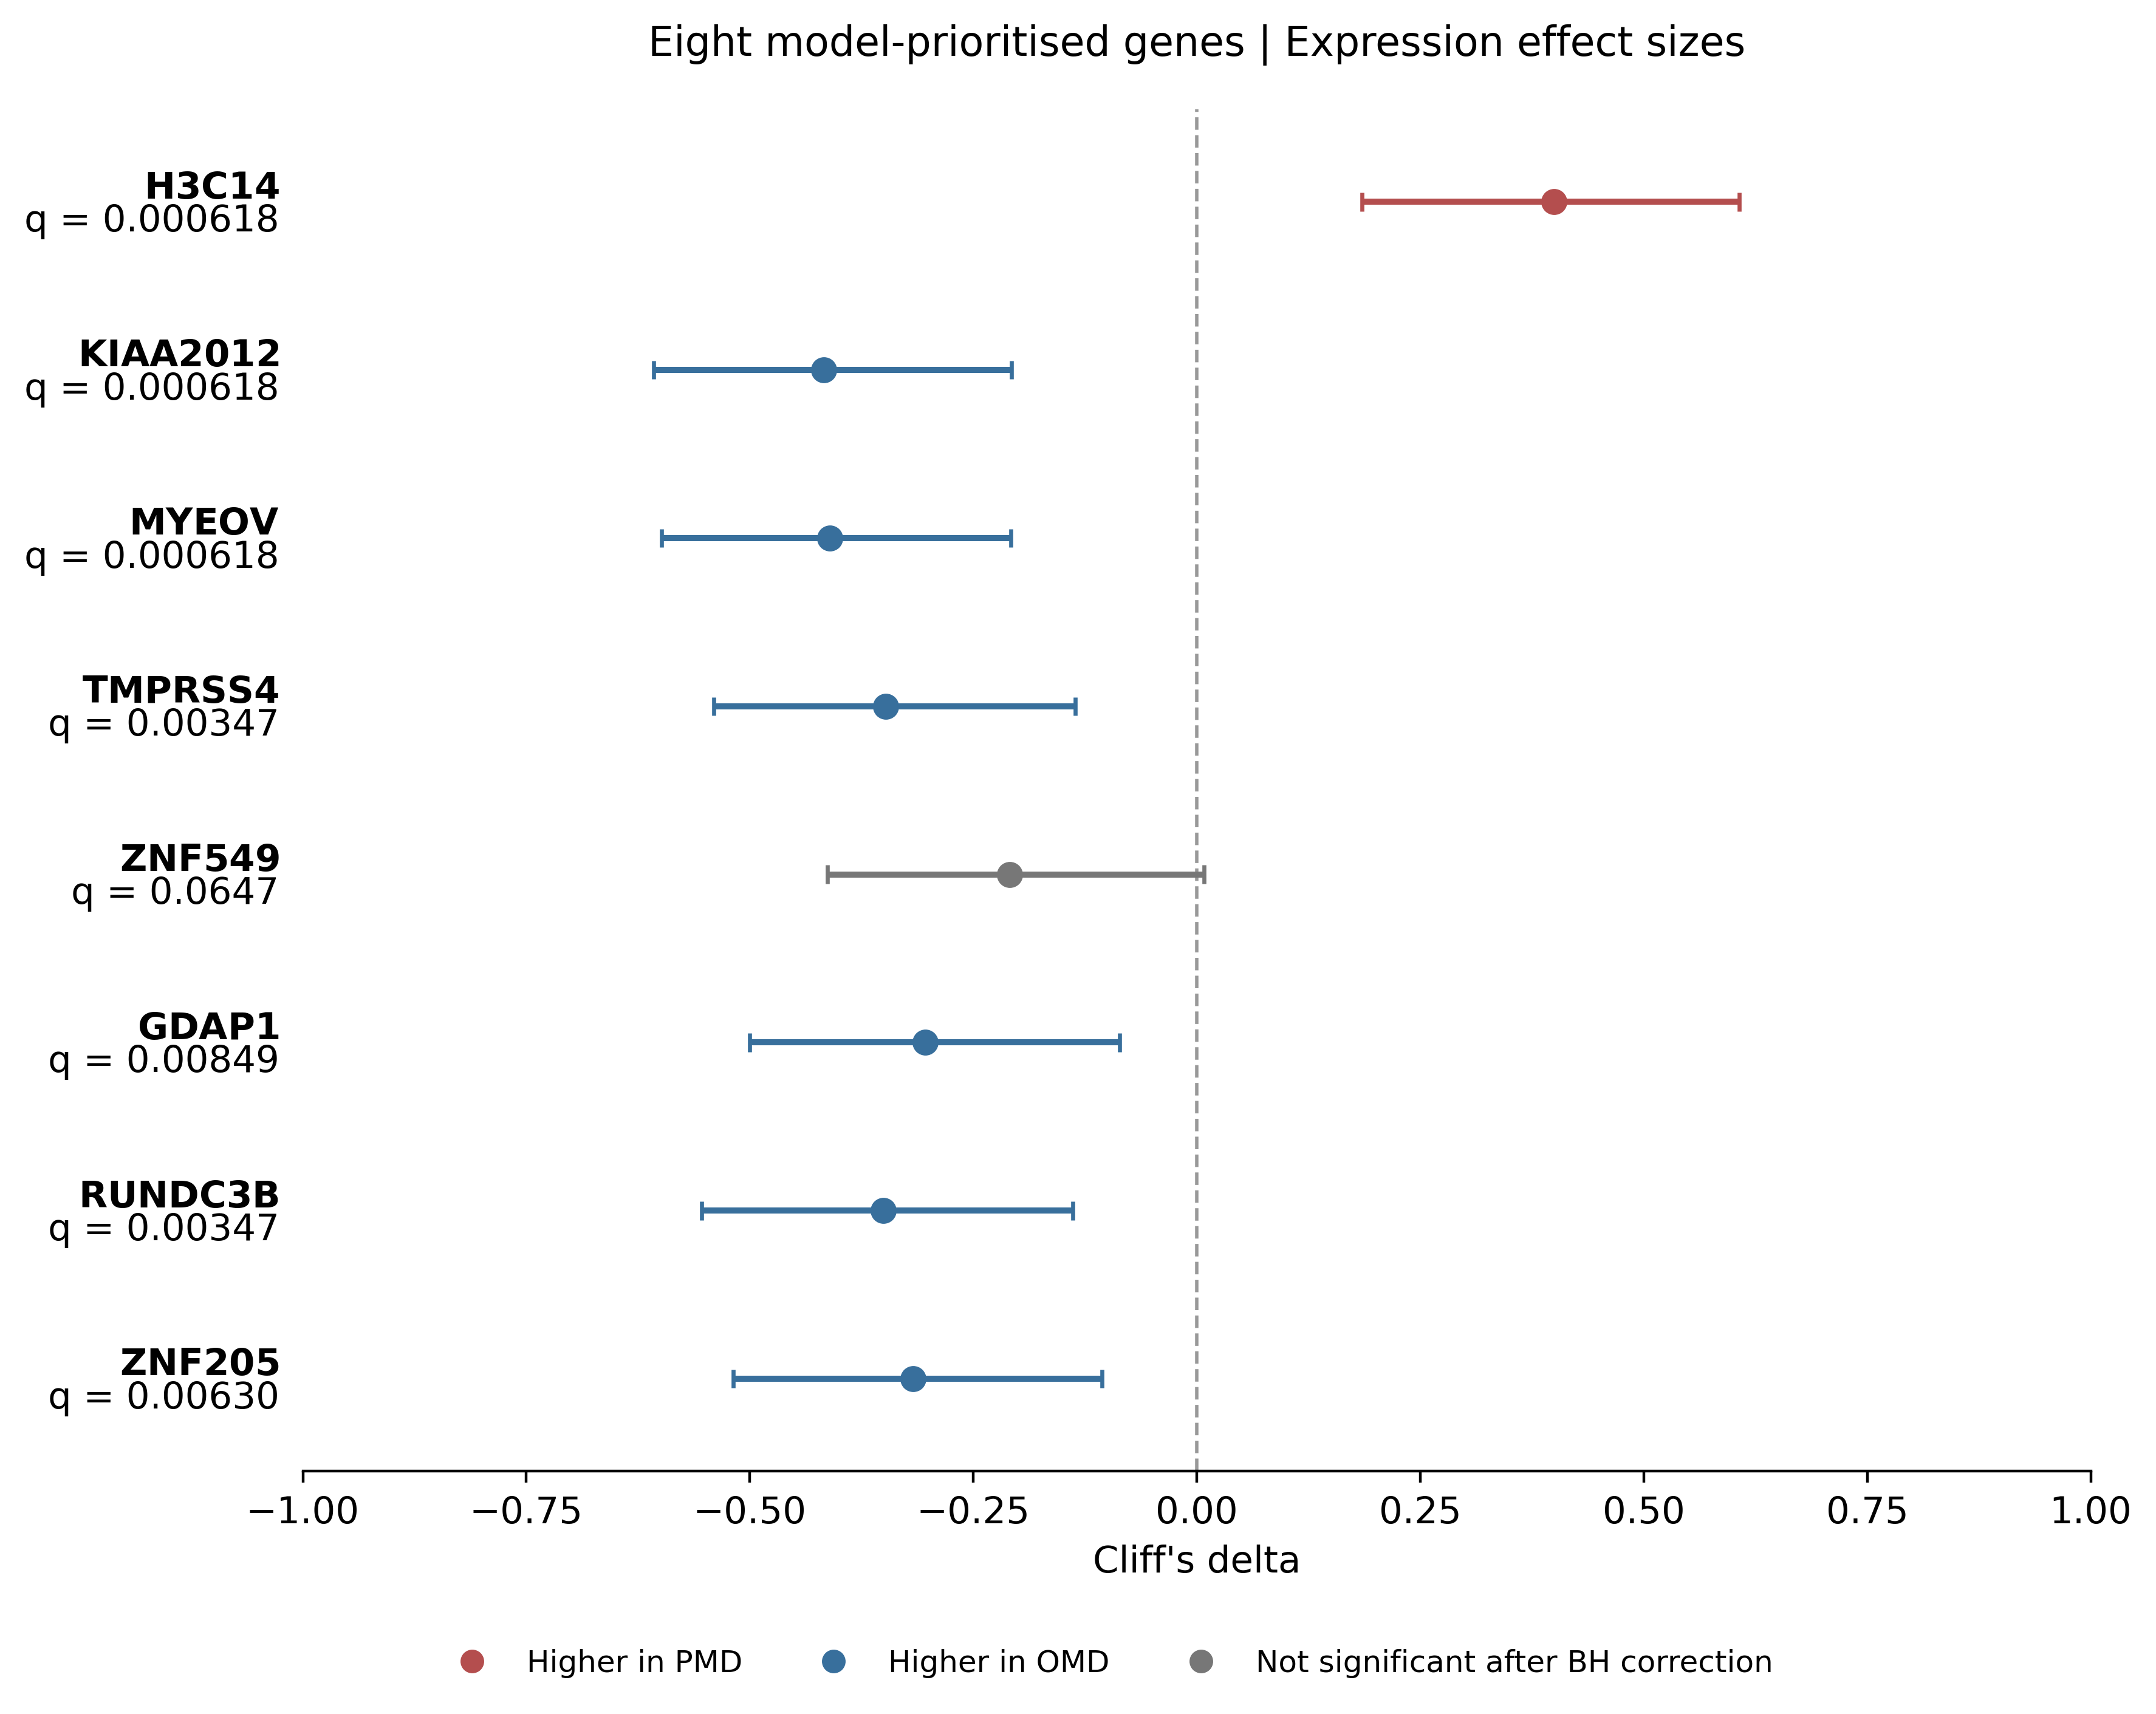

In [26]:
results = pd.read_csv(Path('/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/MCPP-Biological-Characterization/common-110/harmonised_main8/harmonised_only_main8_expression_tests.csv'))
assert results.gene_symbol.tolist() == ['H3C14', 'KIAA2012', 'MYEOV', 'TMPRSS4', 'ZNF549', 'GDAP1', 'RUNDC3B', 'ZNF205']
# Presentation only: all effect estimates, intervals and BH values are preserved.
colours = ['#777777' if r.q_value >= .05 else ('#b44e4e' if r.cliffs_delta > 0 else '#386f9c') for r in results.itertuples()]
with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 11, 'mathtext.fontset': 'dejavusans'}):
    fig, ax = plt.subplots(figsize=(9, 7.2))
    for y, (r, colour) in enumerate(zip(results.itertuples(), colours)):
        ax.hlines(y, r.delta_CI_lower, r.delta_CI_upper, color=colour, linewidth=1.8)
        ax.vlines([r.delta_CI_lower, r.delta_CI_upper], y-.055, y+.055, color=colour, linewidth=1.2)
        ax.scatter(r.cliffs_delta, y, color=colour, s=45, zorder=3)
    labels = [r'$\mathbf{' + r.gene_symbol + '}$' + f'\nq = {r.q_value:#.3g}' for r in results.itertuples()]
    ax.set(yticks=np.arange(8), yticklabels=labels, xlim=(-1, 1), ylim=(7.55, -.55), xlabel="Cliff's delta")
    ax.axvline(0, color='#999999', linestyle='--', linewidth=1, zorder=0)
    ax.set_title('Eight model-prioritised genes | Expression effect sizes', fontsize=12, pad=16)
    ax.tick_params(axis='y', length=0, pad=7, labelsize=11)
    for label in ax.get_yticklabels():
        label.set_linespacing(0.90)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.legend(handles=[
        Line2D([], [], marker='o', color='#b44e4e', linestyle='none', label='Higher in PMD'),
        Line2D([], [], marker='o', color='#386f9c', linestyle='none', label='Higher in OMD'),
        Line2D([], [], marker='o', color='#777777', linestyle='none', label='Not significant after BH correction'),
    ], loc='upper center', bbox_to_anchor=(.45, -.11), ncol=3, frameon=False, fontsize=9)
    fig.tight_layout()
    output_dir = ROOT / 'figures/results/biological_interpretation'
    output_dir.mkdir(parents=True, exist_ok=True)
    figure_png = output_dir / 'harmonised_only_main8_cliffs_delta_BH_direction_bold_genes.png'
    figure_pdf = output_dir / 'harmonised_only_main8_cliffs_delta_BH_direction_bold_genes.pdf'
    fig.savefig(figure_png, dpi=400, bbox_inches='tight')
    fig.savefig(figure_pdf, bbox_inches='tight')
    plt.show()


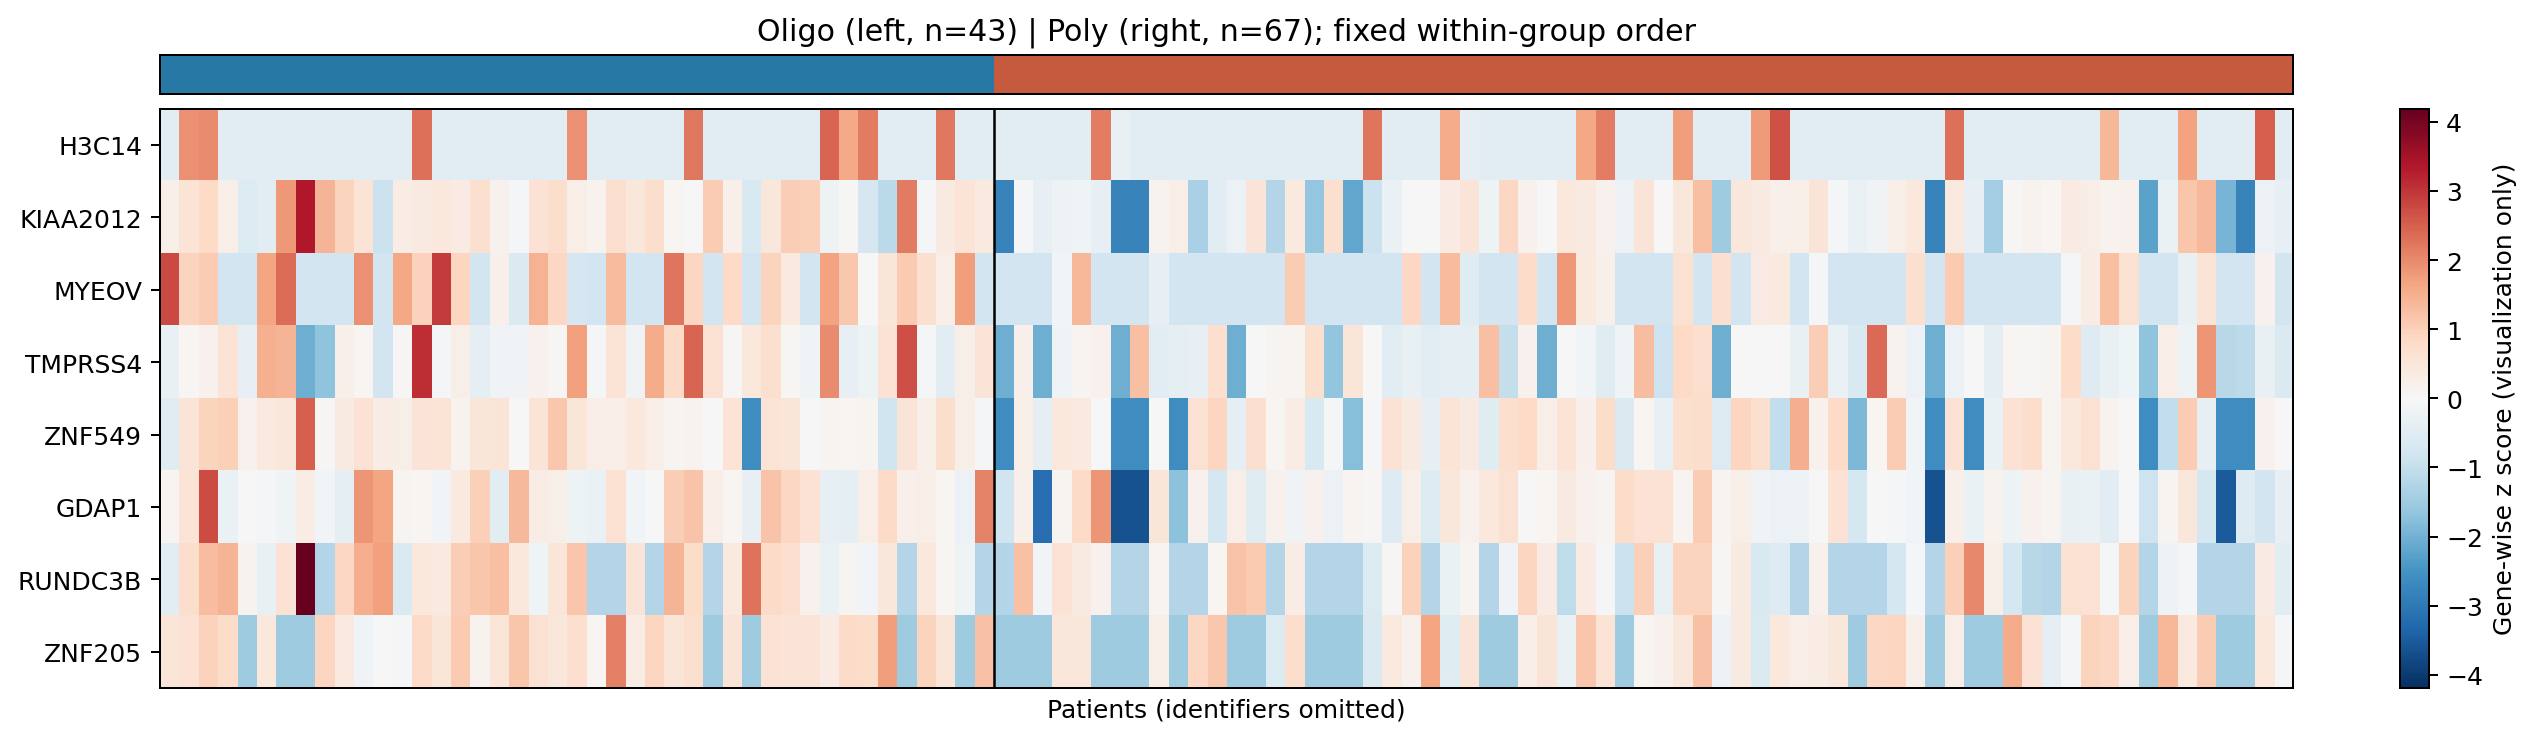

In [ ]:
display(Image(filename=str(RESULTS / 'harmonised_only_main8_heatmap.png')))

## Main expression results

Seven of eight genes meet BH q<0.05. H3C14 is higher in poly; KIAA2012, MYEOV, TMPRSS4, GDAP1, RUNDC3B and ZNF205 are higher in oligo. ZNF549 does not pass correction (q=0.0647), and its effect interval includes zero. Selection on metastatic phenotype makes these descriptive post-selection findings.